# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [10]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

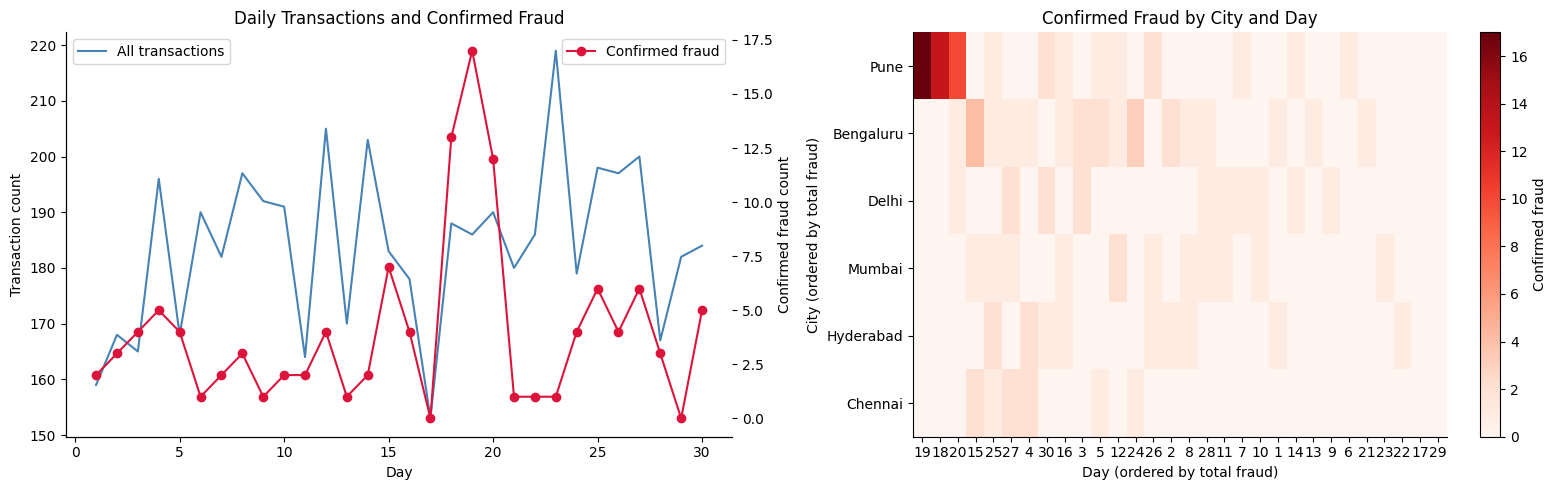

Top city-day fraud counts:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Chennai    4       2
Bengaluru  3       2
Hyderabad  25      2
Pune       26      2
Chennai    15      2
Name: is_fraud, dtype: int64


In [11]:
import matplotlib.pyplot as plt

# Daily transaction counts and confirmed fraud
daily_total = tx.groupby("day")["txn_id"].size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()

# Create the figure and axes FIRST
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Daily transaction count and fraud count
axes[0].plot(
    daily_total.index,
    daily_total.values,
    color="steelblue",
    label="All transactions"
)

axes[0].set_ylabel("Transaction count")
axes[0].set_xlabel("Day")
axes[0].legend(loc="upper left")

ax2 = axes[0].twinx()

ax2.plot(
    daily_fraud.index,
    daily_fraud.values,
    color="crimson",
    marker="o",
    label="Confirmed fraud"
)

ax2.set_ylabel("Confirmed fraud count")
ax2.legend(loc="upper right")
axes[0].set_title("Daily Transactions and Confirmed Fraud")

# Plot 2: City × day fraud heatmap
heat = tx.pivot_table(
    index="city",
    columns="day",
    values="is_fraud",
    aggfunc="sum",
    fill_value=0
)

# Reorder cities and days by total fraud
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(heat, aspect="auto", cmap="Reds")

axes[1].set_title("Confirmed Fraud by City and Day")
axes[1].set_xlabel("Day (ordered by total fraud)")
axes[1].set_ylabel("City (ordered by total fraud)")

axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)

axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)

plt.colorbar(im, ax=axes[1], label="Confirmed fraud")

plt.tight_layout()
plt.show()

# Print the highest-fraud city-day combinations
hotspots = (
    tx.groupby(["city", "day"])["is_fraud"]
      .sum()
      .sort_values(ascending=False)
)

print("Top city-day fraud counts:")
print(hotspots.head(10))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview reveals a concentration of confirmed fraud in Pune on days 18–20, which would be difficult to recognise from a list sorted only by detector score. Reordering the city-by-day matrix makes this pattern visually prominent. This is an example of exploratory pattern discovery through reordering

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

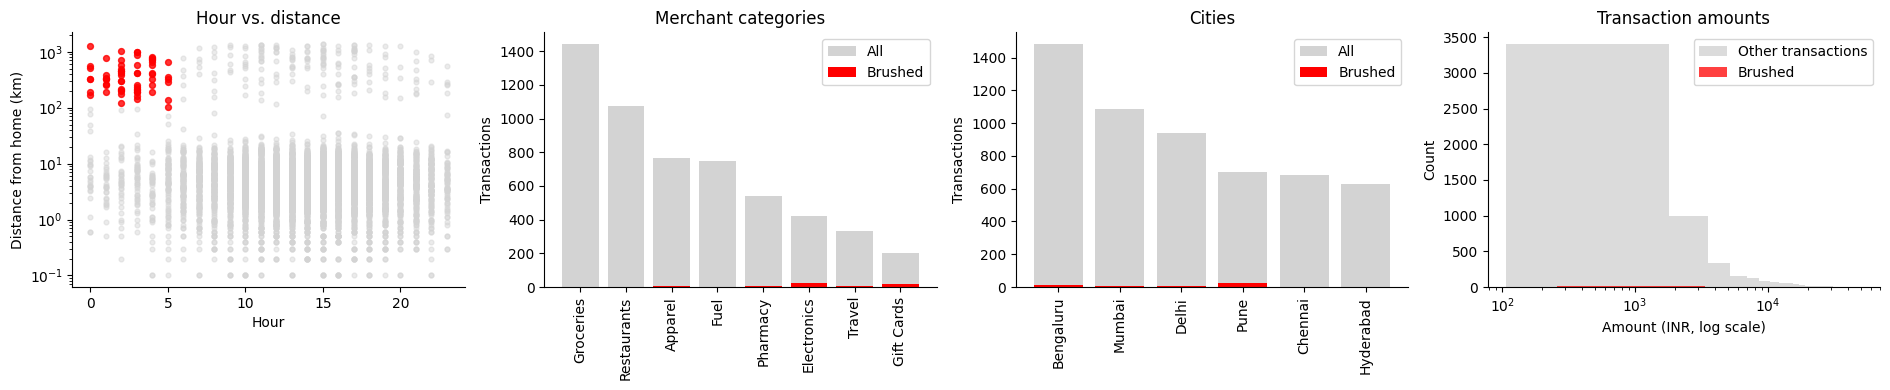

Brushed transactions: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured: 44.17%


In [12]:
# TODO 1: Define the brush
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

# TODO 2: Four coordinated views
fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# (a) Hour vs. distance, with logarithmic y-axis
axes[0].scatter(
    tx.loc[~brush, "hour"],
    tx.loc[~brush, "distance_from_home_km"],
    color="lightgrey", alpha=0.45, s=12, label="Other transactions"
)
axes[0].scatter(
    tx.loc[brush, "hour"],
    tx.loc[brush, "distance_from_home_km"],
    color="red", alpha=0.8, s=18, label="Brushed"
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs. distance")

# (b) Merchant category counts
categories = tx["merchant_category"].value_counts().index
all_cat = tx["merchant_category"].value_counts().reindex(categories, fill_value=0)
brush_cat = tx.loc[brush, "merchant_category"].value_counts().reindex(categories, fill_value=0)

axes[1].bar(categories, all_cat, color="lightgrey", label="All")
axes[1].bar(categories, brush_cat, color="red", label="Brushed")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("Merchant categories")
axes[1].set_ylabel("Transactions")
axes[1].legend()

# (c) City counts
all_city = tx["city"].value_counts()
brush_city = tx.loc[brush, "city"].value_counts().reindex(all_city.index, fill_value=0)

axes[2].bar(all_city.index, all_city.values, color="lightgrey", label="All")
axes[2].bar(brush_city.index, brush_city.values, color="red", label="Brushed")
axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("Cities")
axes[2].set_ylabel("Transactions")
axes[2].legend()

# (d) Amount histogram, logarithmic x-axis
axes[3].hist(
    tx.loc[~brush, "amount_inr"],
    bins=30, color="lightgrey", alpha=0.8, label="Other transactions"
)
axes[3].hist(
    tx.loc[brush, "amount_inr"],
    bins=30, color="red", alpha=0.75, label="Brushed"
)
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Count")
axes[3].set_title("Transaction amounts")
axes[3].legend()

plt.tight_layout()
plt.show()

# TODO 3: Summary statistics
n_brushed = int(brush.sum())
fraud_inside = tx.loc[brush, "is_fraud"].mean()
fraud_overall = tx["is_fraud"].mean()
fraud_captured = (
    tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum()
)

print(f"Brushed transactions: {n_brushed}")
print(f"Fraud rate inside brush: {fraud_inside:.2%}")
print(f"Overall fraud rate: {fraud_overall:.2%}")
print(f"Share of all fraud captured: {fraud_captured:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush selects 61 transactions, of which 86.89% are confirmed fraud. It captures 53 of the 120 confirmed fraud cases, or 44.17% of all fraud. Therefore, the rule identifies a high-risk group but misses more than half of the confirmed cases. The linked city and merchant-category views help investigators investigate where the remaining fraud is concentrated instead of relying on this rule alone.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [13]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Best of five filter timings
times = []

for _ in range(5):
    start = time.perf_counter()
    mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    _ = big.loc[mask]
    elapsed = time.perf_counter() - start
    times.append(elapsed)

best_s = min(times)

# TODO 2: Per-row cost and maximum rows within 0.1 seconds
per_item_us = best_s / len(big) * 1_000_000
max_rows = 0.1 / (per_item_us / 1_000_000)

# TODO 3: Estimate for 50 million rows
t_50m = 50_000_000 * per_item_us / 1_000_000
skip_pct = max(0, (1 - 0.1 / t_50m) * 100)

print(
    f"{len(big):,} rows in {best_s*1000:.1f} ms "
    f"-> {per_item_us:.4f} us/row "
    f"-> max {max_rows:,.0f} rows in 0.1 s"
)
print(
    f"50M rows -> {t_50m:.2f} s; "
    f"must skip {skip_pct:.1f}% of rows to stay under 0.1 s"
)

1,004,640 rows in 13.0 ms -> 0.0129 us/row -> max 7,750,985 rows in 0.1 s
50M rows -> 0.65 s; must skip 84.5% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
A reduction technique is aggregation: precompute summaries by time period, city, or merchant category, and display those summaries during initial exploration. This reduces the amount of data that must be processed for each slider movement, helping the interface remain responsive. The trade-off is that individual transaction details are hidden until the analyst drills down to the underlying records.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532



Capacity-constrained choice:
threshold      0.800000
alerts       144.000000
TP            84.000000
FP            60.000000
FN            36.000000
precision      0.583333
recall         0.700000
F1             0.636364
Name: 15, dtype: float64

Best-F1 choice:
threshold      0.850000
alerts       128.000000
TP            79.000000
FP            49.000000
FN            41.000000
precision      0.617188
recall         0.658333
F1             0.637097
Name: 16, dtype: float64


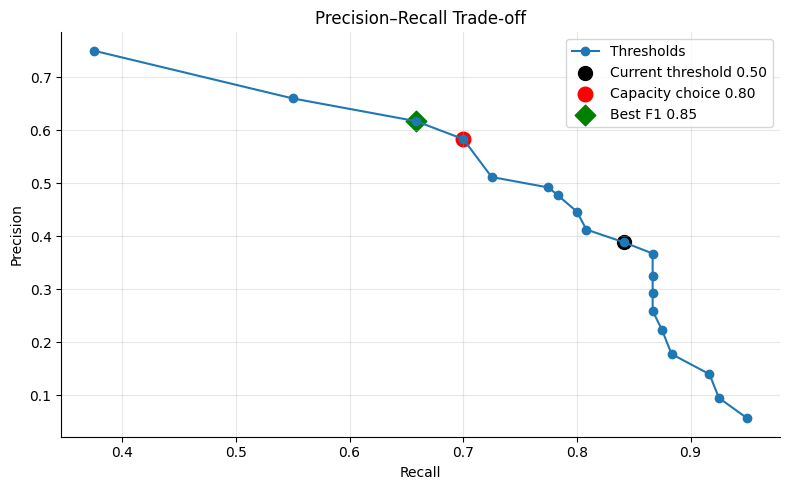

Recommendation: use threshold 0.80; it generates 144 alerts, with precision 58.3% and recall 70.0%, meeting the 150-alert capacity.


In [14]:
rows = []

# TODO 1: Calculate metrics for each threshold
for th in np.round(np.arange(0.05, 1.00, 0.05), 2):
    flag = tx["detector_score"] >= th

    tp = int((flag & (tx["is_fraud"] == 1)).sum())
    fp = int((flag & (tx["is_fraud"] == 0)).sum())
    fn = int((~flag & (tx["is_fraud"] == 1)).sum())

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    rows.append({
        "threshold": th,
        "alerts": tp + fp,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Highest recall within capacity and highest F1
within_capacity = pr[pr["alerts"] <= 150]

capacity_choice = within_capacity.sort_values(
    ["recall", "threshold"],
    ascending=[False, False]
).iloc[0]

best_f1 = pr.loc[pr["F1"].idxmax()]

display(pr.round(3))

print("\nCapacity-constrained choice:")
print(capacity_choice)

print("\nBest-F1 choice:")
print(best_f1)

# TODO 3: Precision-recall curve with three choices
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pr["recall"], pr["precision"],
    marker="o", label="Thresholds"
)

current = pr.loc[np.isclose(pr["threshold"], 0.50)].iloc[0]

ax.scatter(
    current["recall"], current["precision"],
    color="black", s=100, label="Current threshold 0.50"
)

ax.scatter(
    capacity_choice["recall"], capacity_choice["precision"],
    color="red", s=110, label=f"Capacity choice {capacity_choice['threshold']:.2f}"
)

ax.scatter(
    best_f1["recall"], best_f1["precision"],
    color="green", s=110, marker="D",
    label=f"Best F1 {best_f1['threshold']:.2f}"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Trade-off")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# TODO 4: Recommendation
print(
    f"Recommendation: use threshold {capacity_choice['threshold']:.2f}; "
    f"it generates {int(capacity_choice['alerts'])} alerts, "
    f"with precision {capacity_choice['precision']:.1%} "
    f"and recall {capacity_choice['recall']:.1%}, "
    f"meeting the 150-alert capacity."
)

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops should make the final decision with support from the model and the visual analytics dashboard. The threshold of 0.80 meets the alert capacity while retaining 70% recall, whereas the best-F1 threshold of 0.85 provides a slightly higher F1 score but lower recall. This is an operational trade-off involving investigator capacity, missed fraud, and false alerts, so it should not be decided by the model alone. Human-in-the-loop analysis lets investigators inspect the evidence and adjust the threshold according to the organisation’s risk tolerance.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [15]:
# TODO 1: Interactive scatter of flagged transactions
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=[
        "txn_id",
        "customer_id",
        "city",
        "merchant_category",
        "distance_from_home_km",
        "detector_score"
    ],
    title="Flagged Transactions — Select, Zoom and Inspect",
    labels={
        "timestamp": "Transaction time",
        "amount_inr": "Amount (INR, log scale)",
        "label": "Investigation label"
    }
)

fig.update_layout(dragmode="select")
fig.show()

# TODO 2: Sunburst for city → merchant category
sun = (
    tx.groupby(["city", "merchant_category"])
      .agg(
          transactions=("txn_id", "size"),
          fraud_rate=("is_fraud", "mean")
      )
      .reset_index()
)

fig_sun = px.sunburst(
    sun,
    path=["city", "merchant_category"],
    values="transactions",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="Fraud Investigation — Drill Down from City to Merchant Category",
    hover_data={
        "transactions": True,
        "fraud_rate": ":.2%"
    }
)

fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips are useful for inspecting one transaction at a time, but examining hundreds of flagged transactions individually is slow and makes it difficult to identify broader patterns. Investigators would have to remember each case while moving between points. The overview-first scatter plot helps them identify clusters and outliers, while the linked city and merchant views reveal where patterns are concentrated. Tooltips should then be used for details-on-demand after the investigator selects a relevant case.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate in Pune on days 18–20: 37.38%
Fraud rate outside that window: 1.48%
Chi-square statistic: 619.294
Chi-square p-value: 1.065e-136


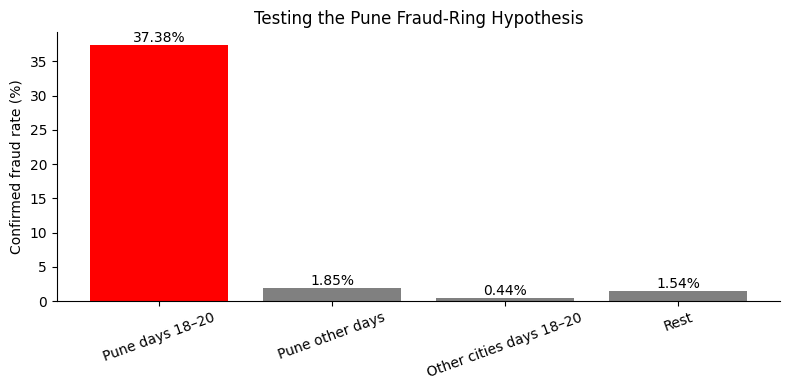


VERDICT
The data supports an unusual concentration of fraud in Pune on days 18–20. This is evidence of a hotspot, not proof of a coordinated criminal ring; further investigation is required.


In [16]:
from scipy.stats import chi2_contingency

# TODO 1: Hypothesis mask
# Hypothesis: a fraud ring operated in Pune on days 18–20.
in_window = (tx["city"] == "Pune") & tx["day"].between(18, 20)

# TODO 2: Fraud rate inside/outside and chi-square test
contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, pval, dof, expected = chi2_contingency(contingency)

inside = tx.loc[in_window]
outside = tx.loc[~in_window]

print(
    f"Fraud rate in Pune on days 18–20: {inside['is_fraud'].mean():.2%}"
)
print(
    f"Fraud rate outside that window: {outside['is_fraud'].mean():.2%}"
)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Chi-square p-value: {pval:.3e}")

# TODO 3: Counter-example searches
pune_other = tx[
    (tx["city"] == "Pune") &
    (~tx["day"].between(18, 20))
]

others_same = tx[
    (tx["city"] != "Pune") &
    tx["day"].between(18, 20)
]

rest = tx[
    (tx["city"] != "Pune") &
    (~tx["day"].between(18, 20))
]

groups = {
    "Pune days 18–20": inside,
    "Pune other days": pune_other,
    "Other cities days 18–20": others_same,
    "Rest": rest
}

# TODO 4: Visual comparison
names = list(groups.keys())
rates = [groups[name]["is_fraud"].mean() * 100 for name in names]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(names, rates, color=["red", "grey", "grey", "grey"])

ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Testing the Pune Fraud-Ring Hypothesis")
ax.tick_params(axis="x", rotation=20)

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# TODO 5: Verdict
print("\nVERDICT")
if pval < 0.05 and inside["is_fraud"].mean() > outside["is_fraud"].mean():
    print(
        "The data supports an unusual concentration of fraud in Pune "
        "on days 18–20. This is evidence of a hotspot, not proof of a "
        "coordinated criminal ring; further investigation is required."
    )
else:
    print(
        "The data does not provide sufficient statistical evidence for "
        "the proposed Pune days 18–20 hotspot."
    )

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_
If Pune had similarly high fraud rates on other days, that would weaken the claim that the hotspot was specific to days 18–20 and support the alternative explanation that Pune has a generally higher fraud rate. If other cities also had high fraud rates on days 18–20, that would suggest a date-related event rather than a Pune-specific hotspot. Neither result alone proves or disproves a coordinated criminal ring, which requires further investigation.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_


The review found 120 confirmed fraud cases among 5,520 transactions, with a pronounced hotspot in Pune on days 18–20, where 40 of 107 transactions were confirmed as fraud. I recommend increasing the alert threshold from 0.50 to 0.80, which generates 144 alerts within the monthly capacity of 150 and achieves 58.33% precision and 70.00% recall. Although a threshold of 0.85 produces the highest F1 score, the 0.80 threshold captures more confirmed fraud and should be selected by Fraud Ops according to its risk tolerance. The first tool to build should be an interactive overview scatter plot with selection, linked city/category views, and transaction tooltips, following Shneiderman’s “overview first, zoom and filter, then details-on-demand” principle. Finally, introduce a human-in-the-loop feedback cycle in which investigators confirm or reject flagged cases, preserve those labels, and use them to retrain and evaluate the detector for the following month.